# Personal Expense Pattern Analysis and Transaction Classification Using Machine Learning

**Purpose:** Explore transaction patterns and test whether transaction records can be classified as *Income* or *Expense*.

> **Important data limitation:** This file contains 277 transactions from 21 Nov 2021 to 2 Mar 2022, spanning only five calendar months, with incomplete March coverage. It is not enough to make a reliable claim about future monthly expenditure. This notebook therefore starts with exploratory spending analysis and a clearly labelled transaction-type classification experiment. We can revisit monthly forecasting only if a more suitable dataset is obtained.

**Reproducibility:** Run the notebook from top to bottom. Metrics and plots are generated from the supplied CSV; no results are hard-coded.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# In Google Colab, upload expense_data_1.csv when prompted.
DATA_PATH = "expense_data_1.csv"
if not Path(DATA_PATH).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except Exception:
        raise FileNotFoundError("Place expense_data_1.csv in the notebook folder or upload it in Colab.")

raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape)
display(raw.head())


Saving expense_data_1.csv to expense_data_1.csv
Raw shape: (277, 11)


,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0


## 1. Data quality checks

In [ ]:
print("Columns:", raw.columns.tolist())
display(pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(1),
    "dtype": raw.dtypes.astype(str)
}))


Columns: ['Date', 'Account', 'Category', 'Subcategory', 'Note', 'INR', 'Income/Expense', 'Note.1', 'Amount', 'Currency', 'Account.1']


,missing_count,missing_percent,dtype
Date,0,0.0,object
Account,0,0.0,object
Category,0,0.0,object
Subcategory,277,100.0,float64
Note,4,1.4,object
INR,0,0.0,float64
Income/Expense,0,0.0,object
Note.1,277,100.0,float64
Amount,0,0.0,float64
Currency,0,0.0,object


## 2. Clean the data

In [ ]:
# Remove entirely empty / duplicated export columns.
data = raw.drop(columns=[c for c in ["Subcategory", "Note.1", "Account.1"] if c in raw.columns], errors="ignore").copy()

data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
# INR and Amount are duplicate-like amount fields in this export. Prefer INR, then Amount if missing.
data["Amount_INR"] = pd.to_numeric(data.get("INR"), errors="coerce")
if "Amount" in data.columns:
    data["Amount_INR"] = data["Amount_INR"].fillna(pd.to_numeric(data["Amount"], errors="coerce"))

data["Category"] = data["Category"].fillna("Unknown").astype(str).str.strip()
data["Note"] = data["Note"].fillna("Unknown").astype(str).str.strip()
data["Account"] = data["Account"].fillna("Unknown").astype(str).str.strip()
data["Transaction_Type"] = data["Income/Expense"].astype(str).str.strip()
data = data.dropna(subset=["Date", "Amount_INR", "Transaction_Type"])
data = data[data["Amount_INR"] >= 0].copy()
data["Month"] = data["Date"].dt.to_period("M").astype(str)
data["DayOfWeek"] = data["Date"].dt.day_name()
data["DayOfMonth"] = data["Date"].dt.day
data["IsWeekend"] = data["Date"].dt.dayofweek >= 5

print("Cleaned shape:", data.shape)
print("Date range:", data["Date"].min(), "to", data["Date"].max())
print("\nTransaction type counts:")
display(data["Transaction_Type"].value_counts().to_frame("count"))
print("\nMonthly record counts:")
display(data.groupby("Month").size().to_frame("transactions"))


Cleaned shape: (277, 14)
Date range: 2021-11-21 13:30:00 to 2022-03-02 10:11:00

Transaction type counts:


,count
Transaction_Type,
Expense,231
Income,46



Monthly record counts:


,transactions
Month,
2021-11,35
2021-12,89
2022-01,92
2022-02,54
2022-03,7


## 3. Exploratory data analysis

Transaction_Type,Expense,Income
Month,,
2021-11,3620.40,4003.0
2021-12,16334.44,12310.0
2022-01,20679.51,19641.0
2022-02,17864.65,18200.0
2022-03,525.00,600.0


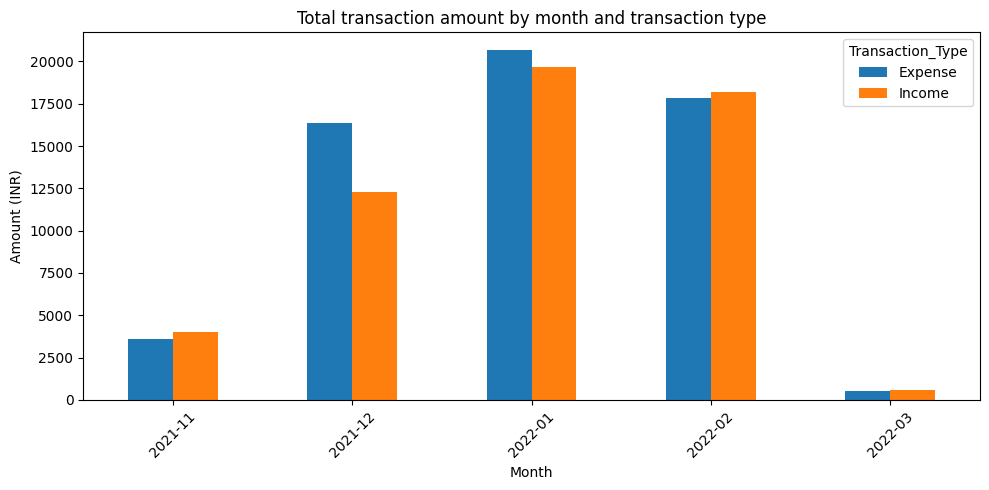

,count,sum,mean
Category,,,
Food,156,24502.48,157.07
Household,6,12188.00,2031.33
Transportation,31,9203.80,296.90
Other,22,5117.00,232.59
Apparel,7,3388.00,484.00
Social Life,5,2513.72,502.74
Education,1,1400.00,1400.00
Self-development,1,400.00,400.00
Beauty,1,196.00,196.00


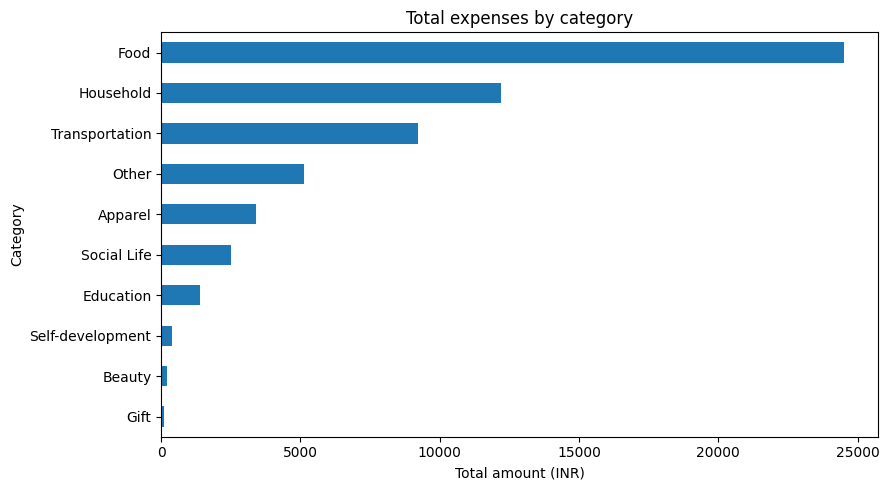

Duplicate rows: 0
Amount summary:


,Amount_INR
count,277.000000
mean,410.750903
std,1065.756569
min,3.000000
25%,50.000000
50%,128.000000
75%,301.150000
max,10000.000000


In [ ]:
# Monthly income and expense totals
monthly = data.pivot_table(index="Month", columns="Transaction_Type", values="Amount_INR", aggfunc="sum", fill_value=0)
display(monthly.round(2))
monthly.plot(kind="bar", figsize=(10, 5))
plt.title("Total transaction amount by month and transaction type")
plt.xlabel("Month")
plt.ylabel("Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Expense categories only
expenses = data[data["Transaction_Type"].str.lower().eq("expense")]
category_totals = expenses.groupby("Category")["Amount_INR"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False)
display(category_totals.round(2))
category_totals["sum"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Total expenses by category")
plt.xlabel("Total amount (INR)")
plt.tight_layout()
plt.show()

print("Duplicate rows:", int(data.duplicated().sum()))
print("Amount summary:")
display(data["Amount_INR"].describe().to_frame("Amount_INR"))


## 4. Machine learning experiment: classify Income vs Expense

We will test a transaction-type classifier. The target is `Transaction_Type`. To reduce direct label leakage, the model will **not** use `Category`, `Account`, or the original `Income/Expense` column as input. It uses amount, date-derived features, and transaction-note text.

This is a small, personal dataset, so the scores are exploratory and may not generalize to other people or future transactions. The split is stratified, and both a simple baseline and a model are evaluated on a held-out test set.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Keep only the two expected classes.
ml = data[data["Transaction_Type"].isin(["Income", "Expense"])].copy()
ml["Note"] = ml["Note"].fillna("Unknown").astype(str)
ml["DayOfWeek"] = ml["Date"].dt.day_name()
ml["MonthNumber"] = ml["Date"].dt.month
ml["DayOfMonth"] = ml["Date"].dt.day

X = ml[["Amount_INR", "MonthNumber", "DayOfMonth", "DayOfWeek", "Note"]]
y = ml["Transaction_Type"]

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError("Not enough examples in each target class for a stratified train/test split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

numeric_features = ["Amount_INR", "MonthNumber", "DayOfMonth"]
categorical_features = ["DayOfWeek"]
text_feature = "Note"

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
        ("day", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("text", TfidfVectorizer(max_features=500, ngram_range=(1, 2)), text_feature),
    ],
    remainder="drop"
)

models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("preprocess", preprocess),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ])
}

rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="weighted", zero_division=0)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Weighted precision": p,
        "Weighted recall": r,
        "Weighted F1": f1
    })
    fitted[name] = model

results = pd.DataFrame(rows).set_index("Model")
display(results.round(3))


,Accuracy,Weighted precision,Weighted recall,Weighted F1
Model,,,,
Majority-class baseline,0.829,0.687,0.829,0.751
Logistic Regression,0.943,0.947,0.943,0.938


## 5. Inspect the test-set results

              precision    recall  f1-score   support

     Expense       0.94      1.00      0.97        58
      Income       1.00      0.67      0.80        12

    accuracy                           0.94        70
   macro avg       0.97      0.83      0.88        70
weighted avg       0.95      0.94      0.94        70



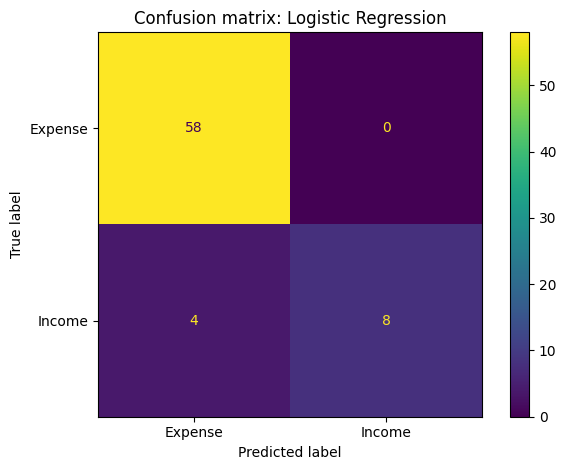

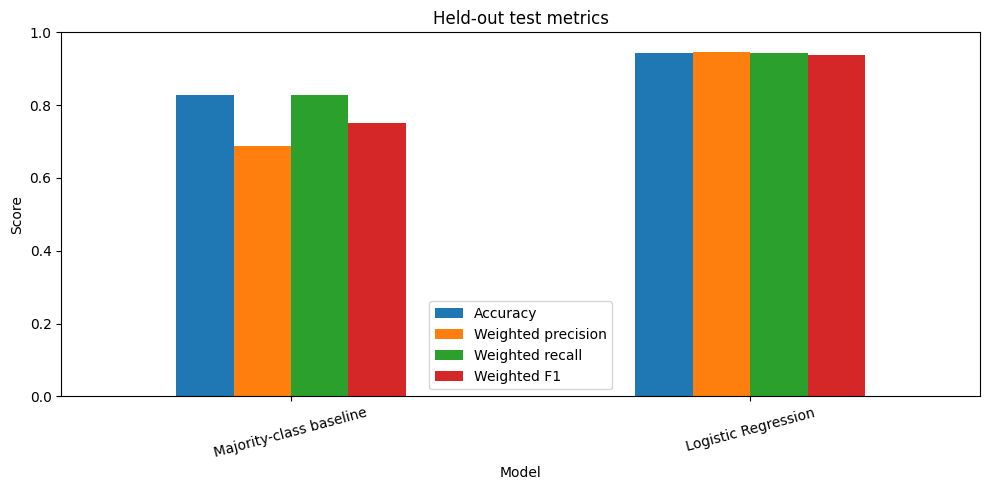

In [ ]:
best_name = "Logistic Regression"
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap=None)
plt.title("Confusion matrix: Logistic Regression")
plt.tight_layout()
plt.show()

results.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Held-out test metrics")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 6. Limitations and conclusion

After running the notebook, report the actual metrics displayed above. Do not copy example scores from elsewhere.

Limitations to discuss:
- Only 277 records are available.
- The data covers about five calendar months, and March is incomplete.
- It appears to represent one person's transactions, not a representative population.
- Some categories are rare and some notes are missing.
- A held-out test set from the same dataset does not establish performance on other users.

**Conclusion template:** “This study explored [actual observed patterns] and evaluated a Logistic Regression classifier against a majority-class baseline for distinguishing income and expense transactions. On the held-out test set, [insert measured metrics]. Due to the small and time-limited dataset, results should be interpreted as exploratory. Future work should use a larger, longer, appropriately licensed dataset and validate the approach on independent data.”

## 7. Export cleaned data


In [ ]:
export_cols = ["Date", "Account", "Category", "Note", "Amount_INR", "Transaction_Type", "Currency", "Month"]
clean_export = data.copy()
if "Currency" not in clean_export.columns:
    clean_export["Currency"] = "INR"
clean_export[export_cols].to_csv("cleaned_expense_data.csv", index=False)
print("Saved cleaned_expense_data.csv")


Saved cleaned_expense_data.csv
